<a href="https://colab.research.google.com/github/bhagathcr/tes_2/blob/master/Thermal_Aware_Power_Budgeting_Simulation(5).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Capstone Project A — Thermal-Aware Power Budgeting on a Chip
**Google Colab simulation notebook | Six-stage mathematical pipeline**

This notebook models steady 2-D heat conduction on a 10 mm × 10 mm die with thermal conductivity 150 W/(m·K), 300 K fixed-temperature boundaries, a 40 × 40 grid, four heat-source blocks, and a 5 W total power budget.

**Explicit assumptions:** the project brief does not specify die thickness or exact block footprints. This runnable model assumes a 0.1 mm thickness and four 4 × 4-cell source regions at different locations inside the die. These assumptions affect the absolute temperatures. The reference temperatures (about 343 K uniform and 327 K optimized) are from the project brief, not guaranteed outputs from this simulation.

The optimization uses **sum of block powers = 5 W** by default, so it compares distributions using the same total power. If only `sum(q) <= 5 W` were used while minimizing peak temperature, the trivial optimum would be zero power.

## Stage 1 — Field model
Fourier’s law: $\mathbf{q}_{heat}=-k\nabla T$. At steady state, energy conservation gives $\nabla\cdot\mathbf{q}_{heat}=Q$. For constant \(k\), this becomes $-k\nabla^2T=Q\ $.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.sparse import diags, kron, eye
from scipy.sparse.linalg import spsolve
from scipy.optimize import linprog

L = 10e-3          # die side length, m
k = 150.0          # W/(m K)
T_amb = 300.0      # K
P_max = 5.0        # W
N = 40             # grid points per side
thickness = 0.1e-3 # assumed thickness: 0.1 mm
block_size = 4     # source patch width/height in grid cells
block_centres = [(N//2,N//2),(N//4,N//4),(N//4,3*N//4),(3*N//4,N//4)]
dx = L/(N-1)
print(f"Grid: {N}×{N}, spacing={dx*1e3:.4f} mm; k={k} W/(m·K); ambient={T_amb} K; budget={P_max} W")
print(f"Assumed die thickness: {thickness*1e3:.2f} mm")

Grid: 40×40, spacing=0.2564 mm; k=150.0 W/(m·K); ambient=300.0 K; budget=5.0 W
Assumed die thickness: 0.10 mm


## Stage 2 — PDE and boundary conditions
Solve the steady 2-D Poisson equation $\nabla^2T=-Q/k$, with Dirichlet boundaries \(T=300\,K\) on all four edges. The unknowns are the interior grid temperatures; solve for temperature rise $\theta=T-T_{amb}$, which is zero on the boundary.

In [2]:
# Positive discrete operator for -Laplacian on the (N-2)×(N-2) interior grid.
n = N-2
Tx = diags([-np.ones(n-1)/dx**2, 2*np.ones(n)/dx**2, -np.ones(n-1)/dx**2], [-1,0,1], format="csr")
Ty = diags([-np.ones(n-1)/dx**2, 2*np.ones(n)/dx**2, -np.ones(n-1)/dx**2], [-1,0,1], format="csr")
A = kron(eye(n, format="csr"), Tx, format="csr") + kron(Ty, eye(n, format="csr"), format="csr")
print("Interior unknowns:", n*n, "| sparse matrix:", A.shape, "| nonzeros:", A.nnz)

Interior unknowns: 1444 | sparse matrix: (1444, 1444) | nonzeros: 7068


## Stage 3 — Transform / thermal impedance
Thermal impedance is $Z_{th}(s)=\Delta T(s)/P(s)$; steady-state behaviour corresponds to the limit $s\to0$. This notebook solves the steady-state PDE directly. A transient simulation would additionally need heat capacity, initial conditions, and a time-dependent power profile, which are not specified in the brief.

## Stage 4 — Finite differences and response matrix
The 5-point finite-difference stencil converts the PDE to a sparse linear system. By linearity, the temperature field can be written $T=T_{amb}+Hq$, where \(q\) is the four-element block-power vector and each column of \(H\) is a unit-watt temperature response.

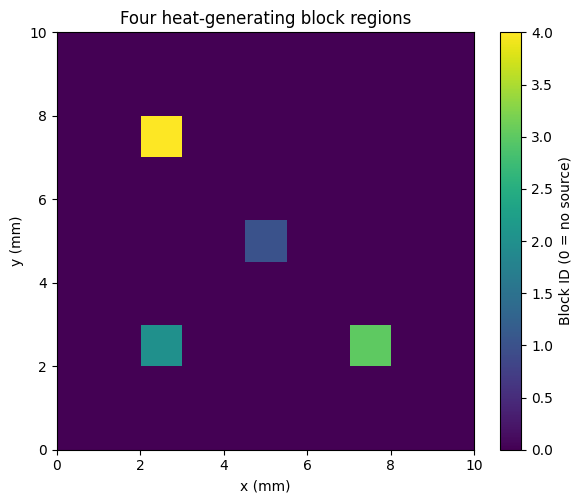

Response matrix for LP: (1600, 4)


In [3]:
def make_block_mask(center, size=block_size):
    r0,c0 = center
    start_r = max(1, r0-size//2); end_r = min(N-1, start_r+size)
    start_c = max(1, c0-size//2); end_c = min(N-1, start_c+size)
    mask = np.zeros((N,N), dtype=bool)
    mask[start_r:end_r,start_c:end_c] = True
    return mask

block_masks = [make_block_mask(c) for c in block_centres]
src = np.zeros((N,N))
for i,m in enumerate(block_masks,1): src[m] = i
plt.figure(figsize=(6,5))
plt.imshow(src, origin="lower", extent=[0,L*1e3,0,L*1e3], interpolation="nearest")
plt.colorbar(label="Block ID (0 = no source)")
plt.xlabel("x (mm)"); plt.ylabel("y (mm)"); plt.title("Four heat-generating block regions")
plt.tight_layout(); plt.show()

def solve_temperature(powers):
    powers = np.asarray(powers, dtype=float)
    Q = np.zeros((N,N))
    for power,mask in zip(powers,block_masks):
        volume = mask.sum()*dx*dx*thickness
        Q[mask] += power/volume
    theta = spsolve(A, (Q[1:-1,1:-1]/k).ravel()).reshape((N-2,N-2))
    T = np.full((N,N), T_amb)
    T[1:-1,1:-1] += theta
    return T

responses = []
for j in range(4):
    q = np.zeros(4); q[j] = 1.0
    responses.append(solve_temperature(q)-T_amb)
H_grid = np.stack(responses)  # shape (4,N,N)
H_flat = H_grid.reshape(4,-1).T
print("Response matrix for LP:", H_flat.shape)

## Stage 5 — Linear programming
Minimize peak-temperature bound \(t\) subject to $T_{amb}+Hq\le t$, $q_i\ge0$, and the power budget. The default enforces $\sum_iq_i=5\,W$ to compare distributions at equal total power.

In [4]:
USE_FULL_POWER_BUDGET = True  # False demonstrates the trivial zero-power optimum for a <= constraint
n_grid = N*N
c_obj = np.array([0.,0.,0.,0.,1.])
A_ub = np.hstack([H_flat, -np.ones((n_grid,1))])
b_ub = -T_amb*np.ones(n_grid)
if USE_FULL_POWER_BUDGET:
    A_eq = np.array([[1.,1.,1.,1.,0.]])
    b_eq = np.array([P_max])
    A_ub_lp, b_ub_lp = A_ub, b_ub
else:
    A_eq = b_eq = None
    A_ub_lp = np.vstack([A_ub,[1.,1.,1.,1.,0.]])
    b_ub_lp = np.r_[b_ub,P_max]
bounds = [(0,None)]*4 + [(T_amb,None)]
result = linprog(c_obj, A_ub=A_ub_lp, b_ub=b_ub_lp, A_eq=A_eq, b_eq=b_eq, bounds=bounds, method="highs")
print("Solver success:", result.success, "|", result.message)
if not result.success: raise RuntimeError(result.message)
q_opt, t_opt = result.x[:4], result.x[4]
print("Optimized block powers (W):", np.round(q_opt,6))
print(f"Total power={q_opt.sum():.6f} W | LP peak bound={t_opt:.4f} K")

Solver success: True | Optimization terminated successfully. (HiGHS Status 7: Optimal)
Optimized block powers (W): [0.801145 1.363879 1.417488 1.417488]
Total power=5.000000 W | LP peak bound=342.0135 K


## Stage 6 — Baseline, results, plots and verification

Uniform peak: 352.9061 K
Optimized peak: 342.0135 K
Peak reduction: 10.8926 K
Power constraint satisfied: True


/tmp/ipykernel_590/3258257037.py:20: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(); plt.show()


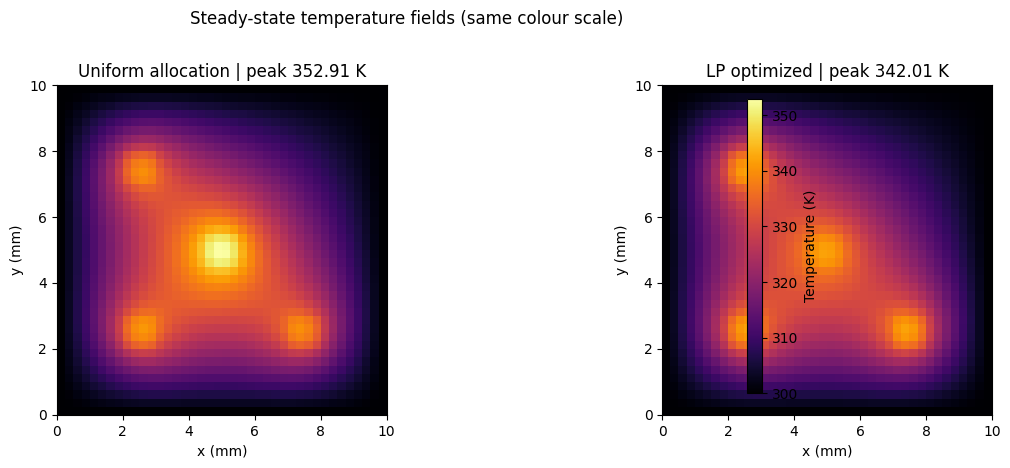

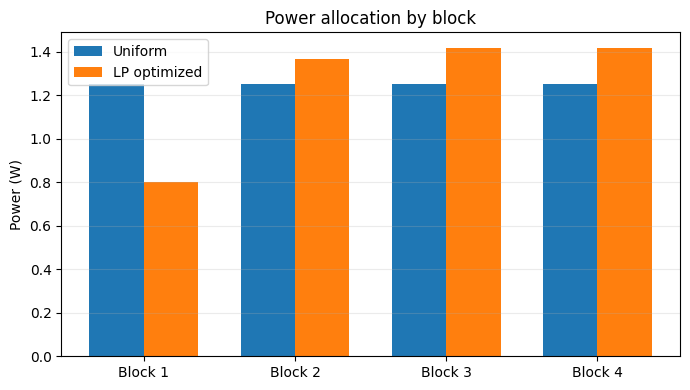

In [5]:
q_uniform = np.full(4,P_max/4) if USE_FULL_POWER_BUDGET else np.zeros(4)
T_uniform = solve_temperature(q_uniform)
T_opt = solve_temperature(q_opt)
peak_uniform, peak_opt = float(T_uniform.max()), float(T_opt.max())
print(f"Uniform peak: {peak_uniform:.4f} K")
print(f"Optimized peak: {peak_opt:.4f} K")
print(f"Peak reduction: {peak_uniform-peak_opt:.4f} K")
print(f"Power constraint satisfied: {q_opt.sum() <= P_max+1e-6}")

vmin, vmax = min(T_uniform.min(),T_opt.min()), max(T_uniform.max(),T_opt.max())
fig,ax = plt.subplots(1,2,figsize=(12,4.5))
im=ax[0].imshow(T_uniform,origin="lower",extent=[0,L*1e3,0,L*1e3],vmin=vmin,vmax=vmax,cmap="inferno")
ax[0].set_title(f"Uniform allocation | peak {peak_uniform:.2f} K")
ax[0].set_xlabel("x (mm)"); ax[0].set_ylabel("y (mm)")
im=ax[1].imshow(T_opt,origin="lower",extent=[0,L*1e3,0,L*1e3],vmin=vmin,vmax=vmax,cmap="inferno")
ax[1].set_title(f"LP optimized | peak {peak_opt:.2f} K")
ax[1].set_xlabel("x (mm)"); ax[1].set_ylabel("y (mm)")
fig.colorbar(im,ax=ax.ravel().tolist(),label="Temperature (K)",shrink=.85)
fig.suptitle("Steady-state temperature fields (same colour scale)",y=1.02)
plt.tight_layout(); plt.show()

x=np.arange(1,5)
plt.figure(figsize=(7,4))
plt.bar(x-.18,q_uniform,width=.36,label="Uniform")
plt.bar(x+.18,q_opt,width=.36,label="LP optimized")
plt.xticks(x,[f"Block {i}" for i in x]); plt.ylabel("Power (W)")
plt.title("Power allocation by block"); plt.legend(); plt.grid(axis="y",alpha=.25)
plt.tight_layout(); plt.show()

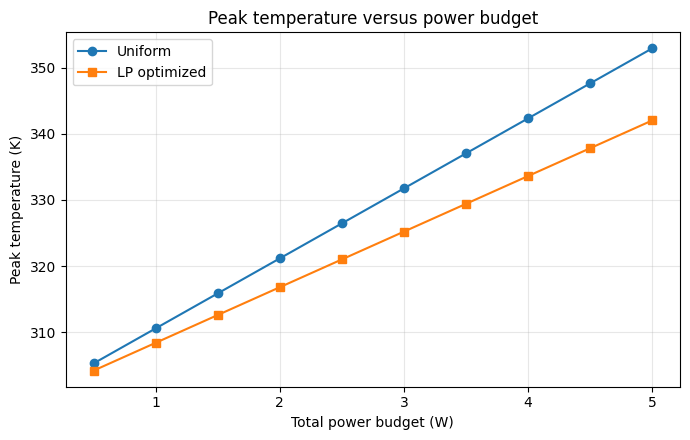


VERIFICATION
LP solver success: True
All powers non-negative: True
Total power <= limit: True
Full budget used: True
Computed optimized peak <= LP bound: True
Reference in project brief (~343 K uniform, ~327 K optimized) is not a guaranteed result; compare against the outputs above.


In [6]:
budgets = np.linspace(0.5,P_max,10)
uniform_peaks, optimal_peaks = [], []
for budget in budgets:
    uniform_peaks.append(solve_temperature(np.full(4,budget/4)).max())
    eq = np.array([[1.,1.,1.,1.,0.]])
    rr = linprog(c_obj,A_ub=A_ub,b_ub=b_ub,A_eq=eq,b_eq=[budget],bounds=bounds,method="highs")
    if not rr.success: raise RuntimeError(rr.message)
    optimal_peaks.append(rr.x[4])
plt.figure(figsize=(7,4.5))
plt.plot(budgets,uniform_peaks,"o-",label="Uniform")
plt.plot(budgets,optimal_peaks,"s-",label="LP optimized")
plt.xlabel("Total power budget (W)"); plt.ylabel("Peak temperature (K)")
plt.title("Peak temperature versus power budget"); plt.grid(alpha=.3); plt.legend()
plt.tight_layout(); plt.show()

print("\nVERIFICATION")
print("LP solver success:", result.success)
print("All powers non-negative:", bool(np.all(q_opt >= -1e-8)))
print("Total power <= limit:", bool(q_opt.sum() <= P_max+1e-6))
if USE_FULL_POWER_BUDGET: print("Full budget used:", bool(np.isclose(q_opt.sum(),P_max,atol=1e-6)))
print("Computed optimized peak <= LP bound:", bool(T_opt.max() <= t_opt+1e-4))
print("Reference in project brief (~343 K uniform, ~327 K optimized) is not a guaranteed result; compare against the outputs above.")

## Limitations and future work
- Assumed 0.1 mm thickness and 4 × 4-cell block footprints because exact values were not specified.
- Fixed 300 K edges idealize the cooling boundary.
- Thermal conductivity is constant.
- Steady-state only; no heat capacity or transient response.
- 40 × 40 grid may introduce discretization error; repeat with finer grids for convergence.
- Future work: use actual block geometry, realistic convection/heat-sink boundary conditions, transient modelling, and grid refinement.

### Figures to use in the presentation
1. Source block map
2. Uniform temperature heatmap
3. LP-optimized temperature heatmap
4. Block power allocation chart
5. Peak temperature versus power budget